# Heart Failure

Queremos predecir la enfermedad cardiaca
Aca es más grave un FN, por lo que se debe obtener un mejor recall.

## Preparamos las librerías

In [86]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import sklearn

RANDOM_STATE = 42

ROOT = Path("..").resolve()     
DATA = ROOT / "data" / "heart.csv"
FIGURES = ROOT / "reports" / "figures"

## 01-Cargamos los datos

In [87]:
df = pd.read_csv(DATA)
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [88]:
df.shape

(918, 12)

In [89]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB


In [90]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


| Variable | Tipo | Significado |
|---|---|---|
| Age | numérica | edad (años) |
| Sex | categórica (M/F) | sexo |
| ChestPainType | categórica (TA, ATA, NAP, ASY) | tipo de dolor torácico |
| RestingBP | numérica | presión arterial en reposo (mm Hg) |
| Cholesterol | numérica | colesterol sérico (mg/dl) |
| FastingBS | binaria (0/1) | glicemia en ayunas > 120 mg/dl |
| RestingECG | categórica (Normal, ST, LVH) | ECG en reposo |
| MaxHR | numérica | frecuencia cardíaca máxima alcanzada |
| ExerciseAngina | binaria (Y/N) | angina inducida por ejercicio |
| Oldpeak | numérica | depresión del segmento ST con el ejercicio |
| ST_Slope | categórica (Up, Flat, Down) | pendiente del segmento ST |
| **HeartDisease** | **objetivo (0/1)** | **enfermedad cardíaca** |

## 02-Calidad de datos

In [91]:
print("Nulos:\n")
print(df.isna().sum())
print("Duplicados:",df.duplicated().sum())

Nulos:

Age               0
Sex               0
ChestPainType     0
RestingBP         0
Cholesterol       0
FastingBS         0
RestingECG        0
MaxHR             0
ExerciseAngina    0
Oldpeak           0
ST_Slope          0
HeartDisease      0
dtype: int64
Duplicados: 0


In [92]:
print(df["HeartDisease"].value_counts())
print("")
print(df["HeartDisease"].value_counts(normalize=True))

HeartDisease
1    508
0    410
Name: count, dtype: int64

HeartDisease
1    0.553377
0    0.446623
Name: proportion, dtype: float64


Vemos que hay 918 filas y 12 columnas. Donde 508 pacientes tienen enfermedad cardiáca (positivo) y 410 no tienen (negativo), su proporción es de aproximadamente del 55 % y 45 %, mostrando clases razonablemente balanceadas.

In [93]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,918.0,53.510893,9.432617,28.0,47.00,54.0,60.0,77.0
RestingBP,918.0,132.396514,18.514154,0.0,120.00,130.0,140.0,200.0
Cholesterol,918.0,198.799564,109.384145,0.0,173.25,223.0,267.0,603.0
FastingBS,918.0,0.233115,0.423046,0.0,0.00,0.0,0.0,1.0
MaxHR,918.0,136.809368,25.460334,60.0,120.00,138.0,156.0,202.0
Oldpeak,918.0,0.887364,1.066570,-2.6,0.00,0.6,1.5,6.2
HeartDisease,918.0,0.553377,0.497414,0.0,0.00,1.0,1.0,1.0


Notemos que para RestingBP el mínimo es 0 y los mismo para Cholesterol, lo cual es imposible. Además Oldpeak tiene valores negativos. Las analizamos.

In [94]:
print((df["RestingBP"] == 0).value_counts())
print((df["RestingBP"] == 0).mean())
print("")
print((df["Cholesterol"] == 0).value_counts())
print((df["Cholesterol"] == 0).mean())
print("")
print((df["Oldpeak"] < 0).value_counts())

RestingBP
False    917
True       1
Name: count, dtype: int64
0.0010893246187363835

Cholesterol
False    746
True     172
Name: count, dtype: int64
0.18736383442265794

Oldpeak
False    905
True      13
Name: count, dtype: int64


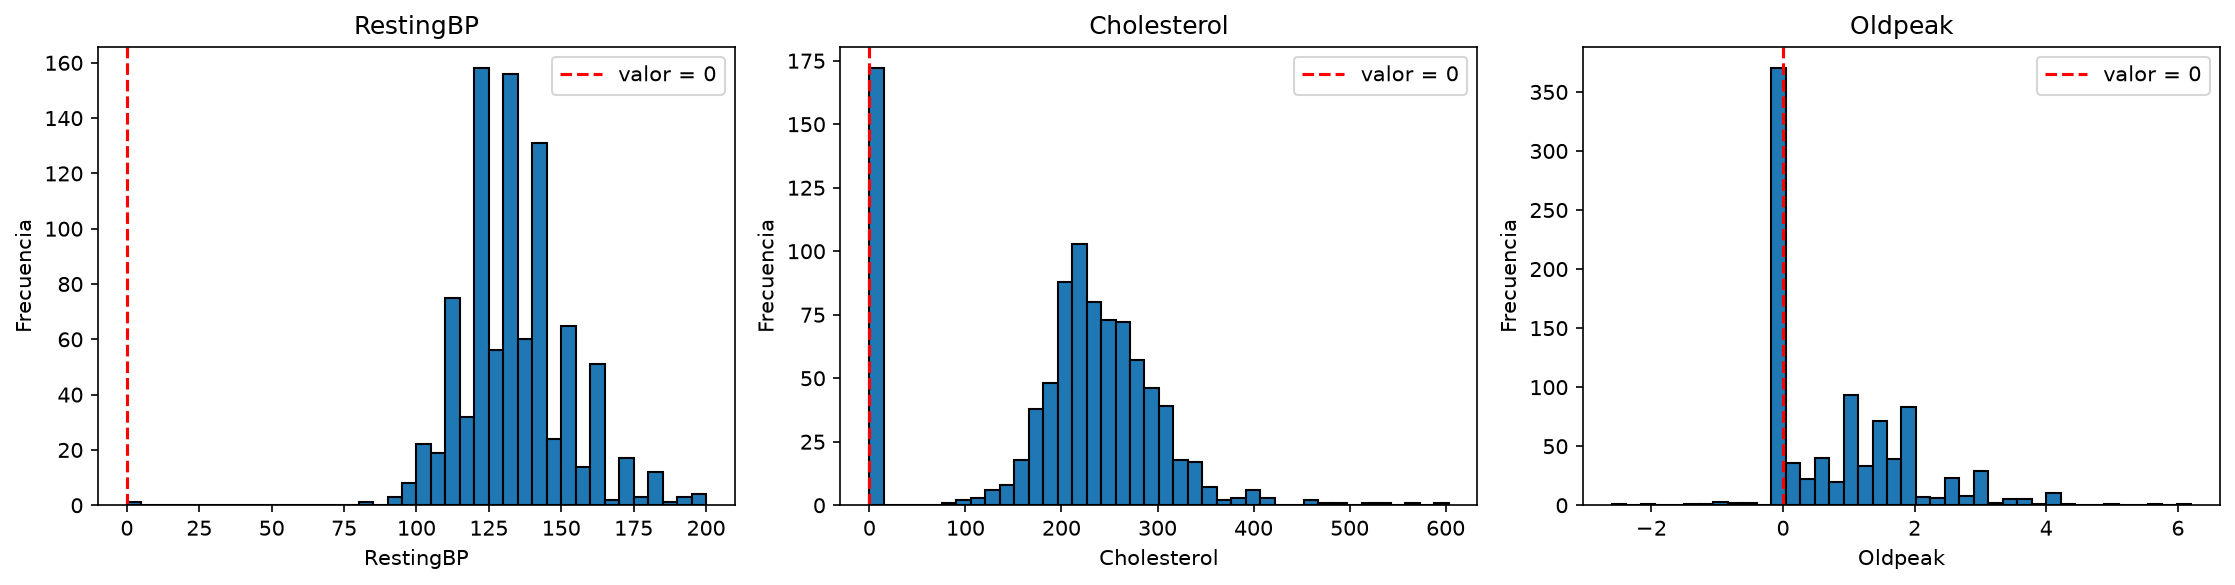

In [95]:
cols = ["RestingBP", "Cholesterol", "Oldpeak"]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, col in zip(axes, cols):
    ax.hist(df[col], bins=40, edgecolor="black")
    ax.axvline(0, color="red", ls="--", label="valor = 0")
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel("Frecuencia")
    ax.legend()

plt.tight_layout()
plt.show()

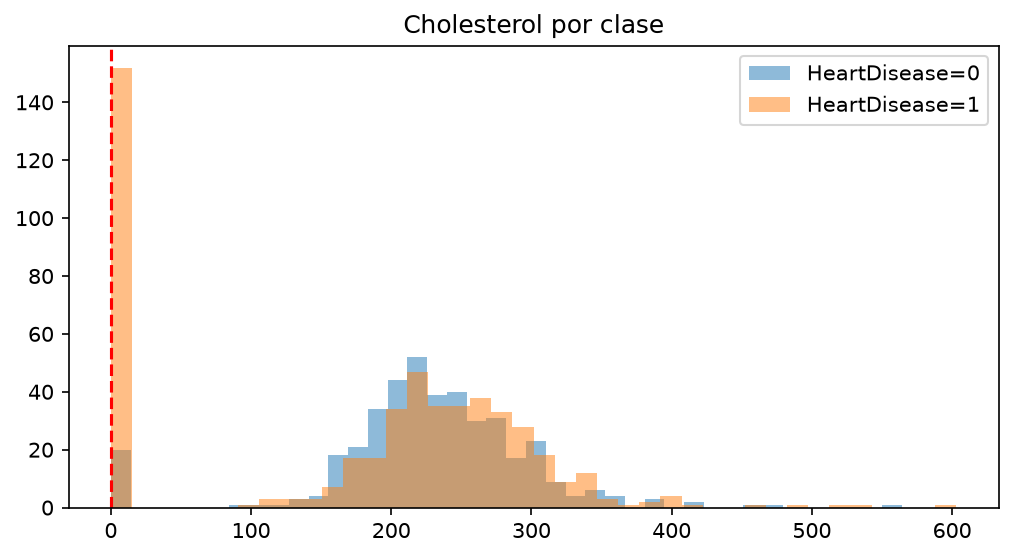

In [75]:
fig, ax = plt.subplots(figsize=(8, 4))
for clase, grupo in df.groupby("HeartDisease"):
    ax.hist(grupo["Cholesterol"], bins=40, alpha=0.5, label=f"HeartDisease={clase}")
ax.axvline(0, color="red", ls="--")
ax.set_title("Cholesterol por clase")
ax.legend()
plt.show()

In [96]:
print(df.groupby(df["Cholesterol"] == 0)["HeartDisease"].mean())

Cholesterol
False    0.477212
True     0.883721
Name: HeartDisease, dtype: float64


De aca vemos que:
- RestingBP tiene un solo valor 0, por lo que probablemente sea un error al introducir el dato. Además representa menos del 5% de los datos, por lo que no hay problema en eliminarla o imputarla.

- Oldpeak es la depresión del segmento ST con el ejercicio, puede tener valores negativos como positivos.

- Cholesterol tiene 172 valores como 0, representando casi un 19% del dataset, por lo que primero, no se debe tomar tan a la ligera imputar o eliminar esas columnas, y segundo, se debe investigar esos valores. Al revisar, el dataset proviene de datos de distintos hospitales, donde en uno de ellos no se midió el cholesterol y en otro parcialmente.

Otro dato importanto es que aproximadamente 88% de los pacientes sin cholesterol medido, tienen la enfermedad.


**Concepto: tipos de datos faltantes.** 
- *MCAR* significa que faltan completamente al azar.
- *MAR* que faltan al azar condicionado a otras variables.
- *MNAR* que faltan por una razón relacionada con el propio valor o con el resultado. 

Aquí no es MCAR, por eso eliminar o imputar a ciegas puede sesgar el modelo.

In [97]:
print(df[df["RestingBP"] == 0].index.tolist())
# 449


[449]


In [98]:
# eliminamos la fila
df = df.drop([449])
print((df["RestingBP"] == 0).value_counts())

RestingBP
False    917
Name: count, dtype: int64


En cuanto a las 172 filas sin cholesterol, lo mejor es no eliminarlos, para evitar un sesgo, y cambiar tan drasticamente la distribución del conjunto de datos. Por lo tanto se imputan los datos. Por ahora simplemente reemplazamos los por Nan.

In [84]:
print((df["Cholesterol"] == 0).value_counts())

Cholesterol
False    746
True     171
Name: count, dtype: int64


In [103]:
df["Cholesterol"] = df["Cholesterol"].replace(0, np.nan)
df["Cholesterol"].isna().sum()

np.int64(171)

## 03-EDA

Realizamos los gráficos univariados para ver las distribuciones

In [ ]:
# quiero graficar las columnas de este dataset

fig, ax = plt.subplots(figsize=(8, 5))
ax =
